In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
satellite_ct_cpp = xr.open_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2007/09/01/CPPin20070901000000405SVMSG01MD.nc")
satellite_ct_ctx = xr.open_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2007/09/01/CTXin20070901000000405SVMSG01MD.nc")

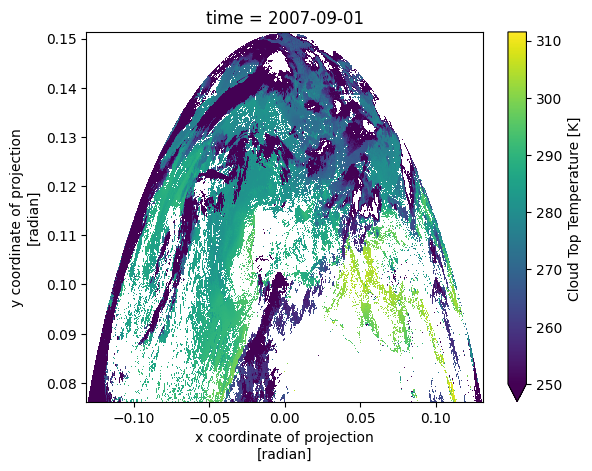

In [3]:
satellite_ct_ctx.ctt.isel(time=0).plot(vmin=250)

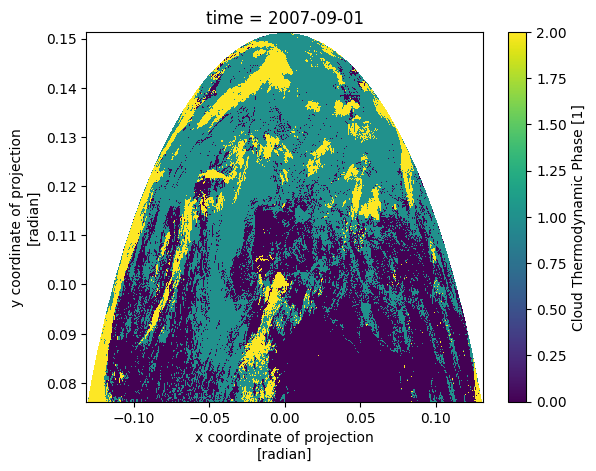

In [4]:
satellite_ct_cpp.cph.isel(time=0).plot()

# Online vs Offline graphs

In [3]:
remap_method = "laf"
online_ct = xr.open_dataset(f"/wolke_scratch/dnikolo/ICON_Data/Testing/online_ct_data/Online_ct_{remap_method}_all_20080902000000.nc")
offline_ct = xr.open_dataset(f"/wolke_scratch/dnikolo/ICON_Data/Testing/offline_ct_data_new/Offline_ct_{remap_method}_all_20080902000000.nc")

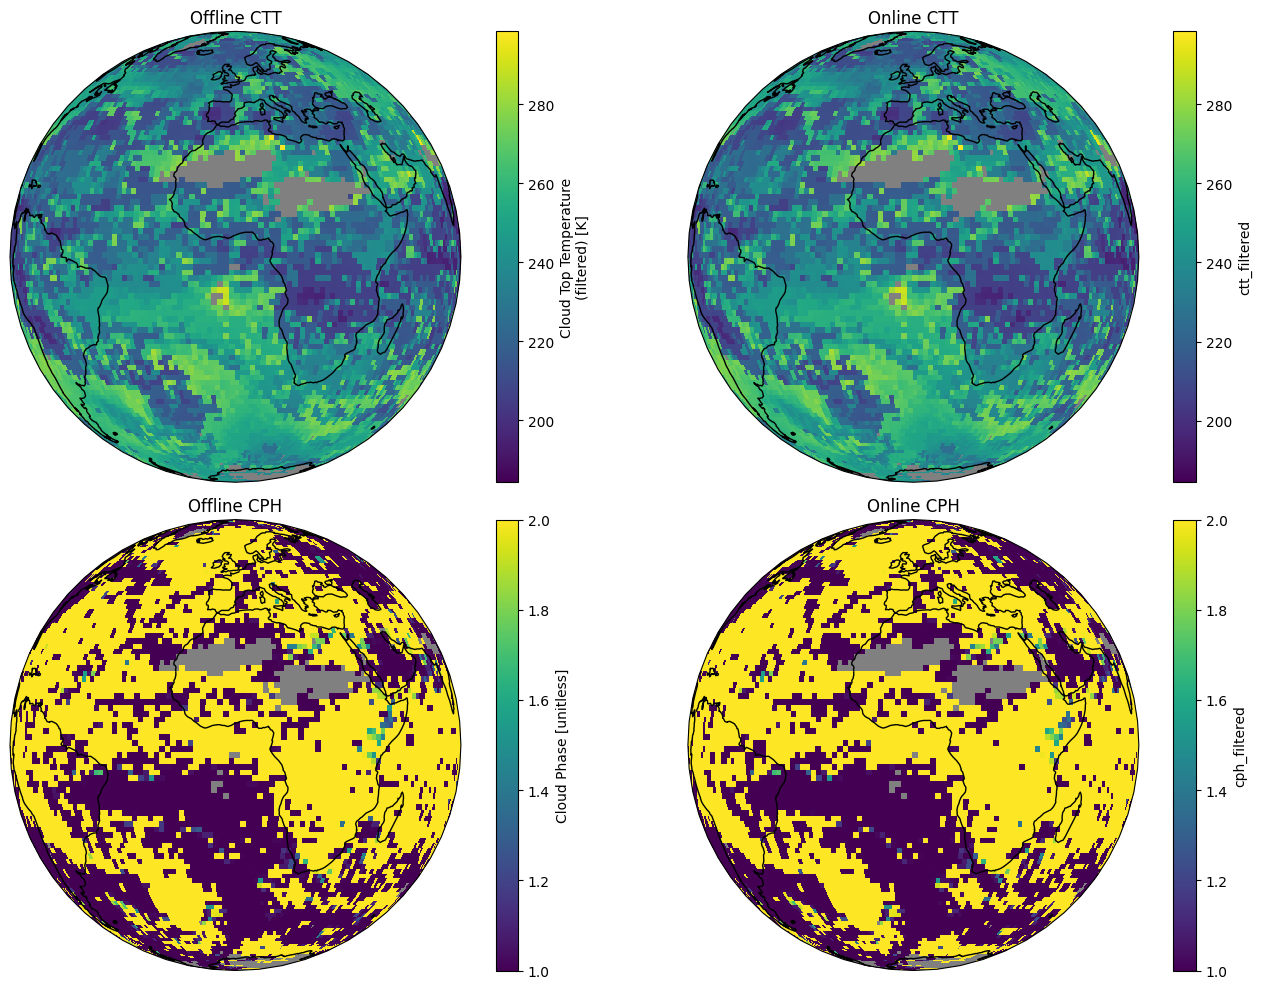

In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Common map projections
map_proj = ccrs.Orthographic(0, 0)
data_proj = ccrs.PlateCarree()

# Create 2x2 figure with cartopy axes
fig, axs = plt.subplots(
    2, 2,
    figsize=(14, 10),
    subplot_kw=dict(projection=map_proj, facecolor="gray")
)

# 1) Offline CTT
offline_ct.ctt_filtered.isel(time=1).plot(
    ax=axs[0, 0],
    transform=data_proj,
    add_colorbar=True
)
axs[0, 0].coastlines()
axs[0, 0].set_title("Offline CTT")

# 2) Online CTT
xr.where(
    online_ct.ctt_filtered > 1,
    online_ct.ctt_filtered,
    np.nan
).isel(time=1).plot(
    ax=axs[0, 1],
    transform=data_proj,
    add_colorbar=True
)
axs[0, 1].coastlines()
axs[0, 1].set_title("Online CTT")

# 3) Offline CPH
offline_ct.cph_filtered.isel(time=1).plot(
    ax=axs[1, 0],
    transform=data_proj,
    add_colorbar=True
)
axs[1, 0].coastlines()
axs[1, 0].set_title("Offline CPH")

# 4) Online CPH
xr.where(
    online_ct.cph_filtered >= 1-1e-5,
    online_ct.cph_filtered,
    np.nan
).isel(time=1).plot(
    ax=axs[1, 1],
    transform=data_proj,
    add_colorbar=True
)
axs[1, 1].coastlines()
axs[1, 1].set_title("Online CPH")

plt.tight_layout()
plt.show()

In [5]:
remap_method = "dis"
online_ct = xr.open_dataset(f"/wolke_scratch/dnikolo/ICON_Data/Testing/online_ct_data/Online_ct_{remap_method}_all_20080902000000.nc")
offline_ct = xr.open_dataset(f"/wolke_scratch/dnikolo/ICON_Data/Testing/offline_ct_data/Offline_ct_{remap_method}_all_20080902000000.nc")

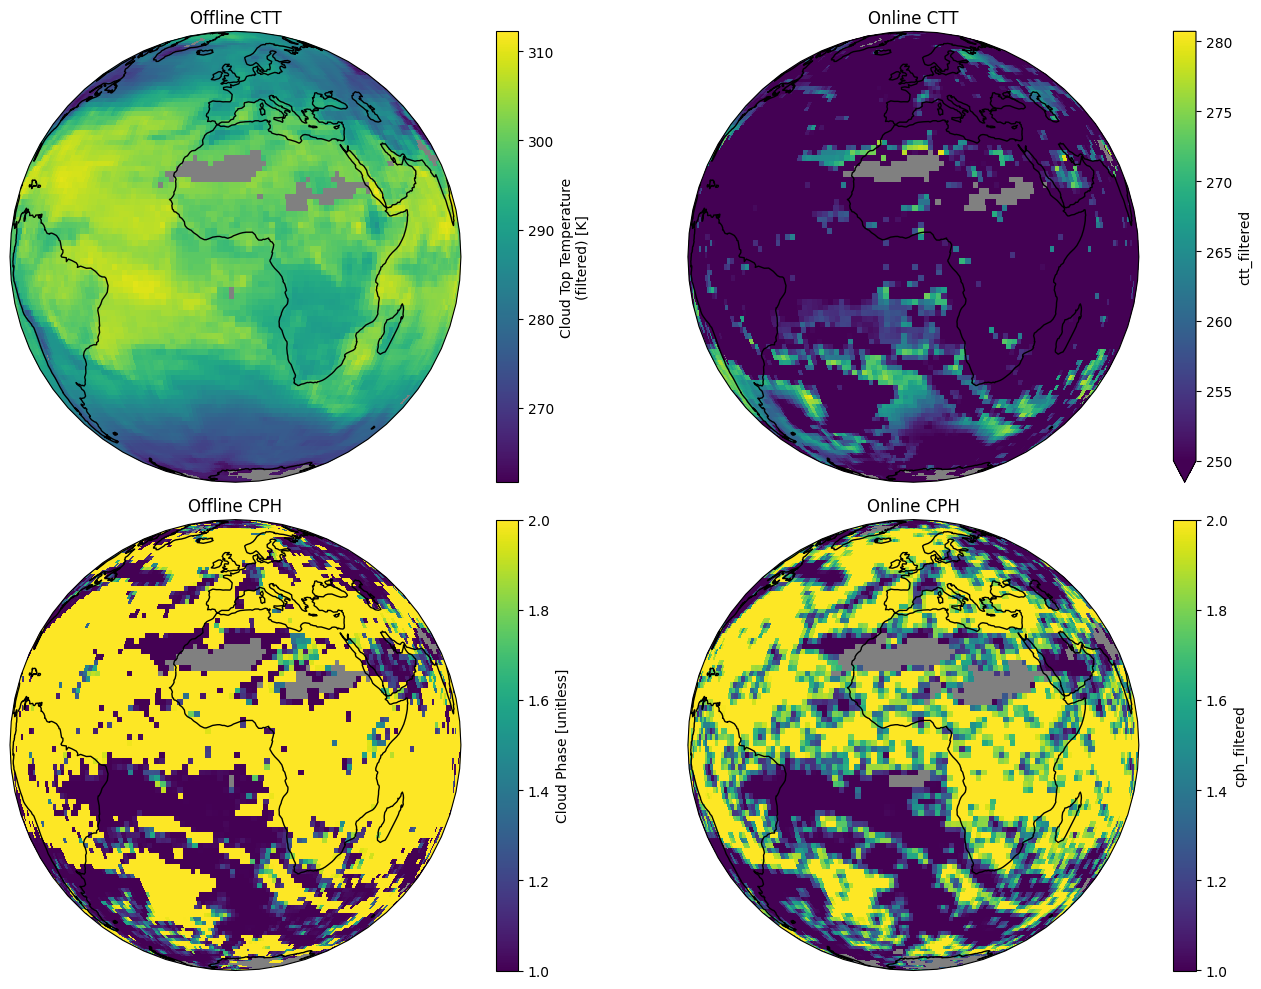

In [6]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Common map projections
map_proj = ccrs.Orthographic(0, 0)
data_proj = ccrs.PlateCarree()

# Create 2x2 figure with cartopy axes
fig, axs = plt.subplots(
    2, 2,
    figsize=(14, 10),
    subplot_kw=dict(projection=map_proj, facecolor="gray")
)

# 1) Offline CTT
offline_ct.ctt_filtered.isel(time=1).plot(
    ax=axs[0, 0],
    transform=data_proj,
    add_colorbar=True
)
axs[0, 0].coastlines()
axs[0, 0].set_title("Offline CTT")

# 2) Online CTT
xr.where(
    online_ct.ctt_filtered > 50,
    online_ct.ctt_filtered,
    np.nan
).isel(time=1).plot(
    ax=axs[0, 1],
    transform=data_proj,
    vmin=250,
    add_colorbar=True
)
axs[0, 1].coastlines()
axs[0, 1].set_title("Online CTT")

# 3) Offline CPH
offline_ct.cph_filtered.isel(time=1).plot(
    ax=axs[1, 0],
    transform=data_proj,
    add_colorbar=True
)
axs[1, 0].coastlines()
axs[1, 0].set_title("Offline CPH")

# 4) Online CPH
xr.where(
    online_ct.cph_filtered >= 1-1e-5,
    online_ct.cph_filtered,
    np.nan
).isel(time=1).plot(
    ax=axs[1, 1],
    transform=data_proj,
    add_colorbar=True
)
axs[1, 1].coastlines()
axs[1, 1].set_title("Online CPH")

plt.tight_layout()
plt.show()

# Development

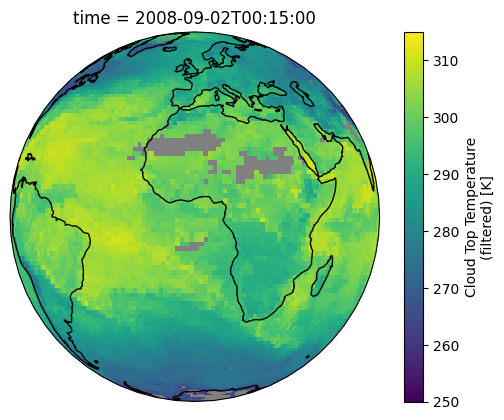

In [11]:
import cartopy.crs as ccrs


p = offline_ct.ctt_filtered.isel(time=1).plot( subplot_kws=dict(projection=ccrs.Orthographic(0, 0), facecolor="gray"), transform=ccrs.PlateCarree(), vmin=250)


p.axes.coastlines()

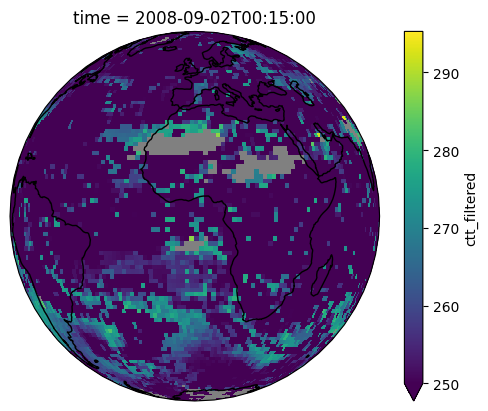

In [12]:

p = xr.where(online_ct.ctt_filtered>1, online_ct.ctt_filtered, np.nan).isel(time=1).plot( subplot_kws=dict(projection=ccrs.Orthographic(0, 0), facecolor="gray"), transform=ccrs.PlateCarree(), vmin=250)
p.axes.coastlines()

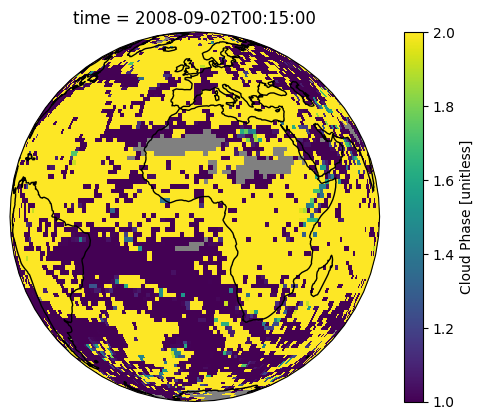

In [13]:
p = offline_ct.cph_filtered.isel(time=1).plot( subplot_kws=dict(projection=ccrs.Orthographic(0, 0), facecolor="gray"), transform=ccrs.PlateCarree())
p.axes.coastlines()

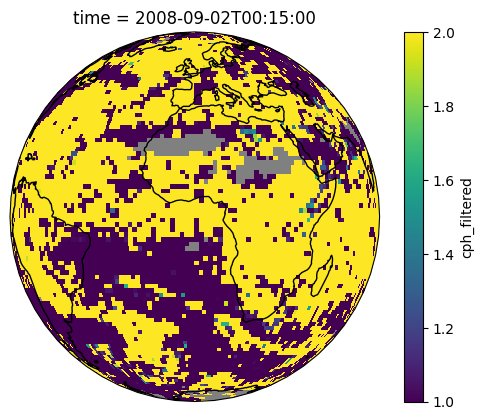

In [14]:
p = xr.where(online_ct.cph_filtered>0.99, online_ct.cph_filtered, np.nan).isel(time=1).plot( subplot_kws=dict(projection=ccrs.Orthographic(0, 0), facecolor="gray"), transform=ccrs.PlateCarree())
p.axes.coastlines()

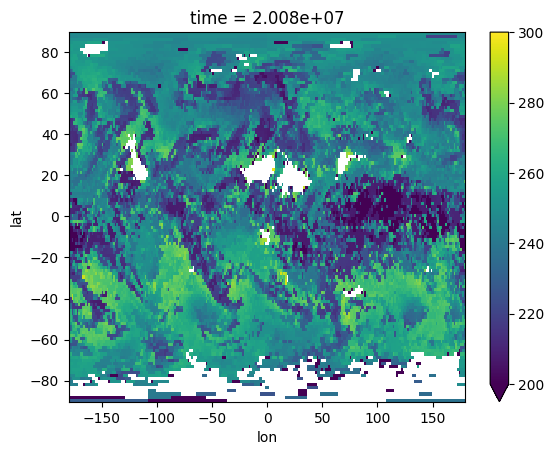

In [30]:
xr.where(online_ct.ctmask>0,  online_ct.ctt, np.nan).isel(time=0).plot(vmin=200, vmax=300)

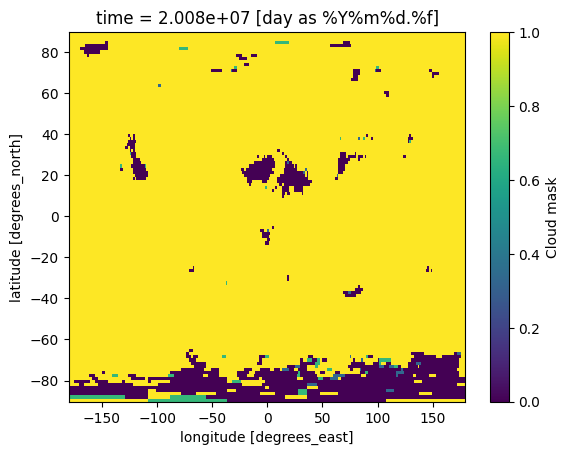

In [19]:
online_ct.ctmask.isel(time=0).plot()

In [4]:
offline_ct

<xarray.Dataset>
Dimensions:       (time: 96, lon: 240, lat: 67)
Coordinates:
  * time          (time) datetime64[ns] 2008-09-01 ... 2008-09-01T23:45:00
  * lon           (lon) float64 -179.5 -178.0 -176.5 ... 176.0 177.5 179.0
  * lat           (lat) float64 -79.0 -77.5 -76.0 -74.5 ... 75.5 77.0 78.5 80.0
Data variables:
    cph_filtered  (time, lat, lon) float64 ...
    ctt_filtered  (time, lat, lon) float64 ...

In [ ]:
offline_3d_data_sample = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/CT_data_from_3d/Filtered_Data/np/2008/09/02/R_Agg_30_T_06_00_20080902010000.nc")
online_

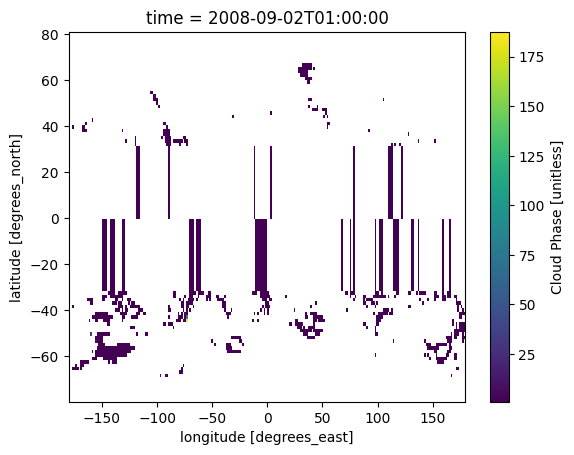

In [3]:
offline_3d_data_sample.isel(time=0)["cph_filtered"].plot()